In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.feature_selection import mutual_info_classif

In [3]:
df = pd.read_csv('../../data/voice.csv')

df.head()

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


In [4]:
print("Ukuran dataset:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())

print("\nJumlah data setiap kelas:")
print(df['label'].value_counts())

df.info()

Ukuran dataset: (3168, 21)

Nama kolom:
['meanfreq', 'sd', 'median', 'Q25', 'Q75', 'IQR', 'skew', 'kurt', 'sp.ent', 'sfm', 'mode', 'centroid', 'meanfun', 'minfun', 'maxfun', 'meandom', 'mindom', 'maxdom', 'dfrange', 'modindx', 'label']

Jumlah data setiap kelas:
label
male      1584
female    1584
Name: count, dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   fl

In [5]:
X = df.drop(columns=['label'])
y = df['label']

print("Jumlah fitur:", X.shape[1])
print("Jumlah data:", X.shape[0])

Jumlah fitur: 20
Jumlah data: 3168


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data training:", X_train.shape)
print("Data testing:", X_test.shape)

Data training: (2534, 20)
Data testing: (634, 20)


In [7]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Normalisasi data selesai.")

Normalisasi data selesai.


In [8]:
knn = KNeighborsClassifier(n_neighbors=3)

knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)

print("Akurasi:", accuracy_score(y_test, y_pred))

Akurasi: 0.9763406940063092


In [9]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      female       0.98      0.97      0.98       317
        male       0.97      0.98      0.98       317

    accuracy                           0.98       634
   macro avg       0.98      0.98      0.98       634
weighted avg       0.98      0.98      0.98       634



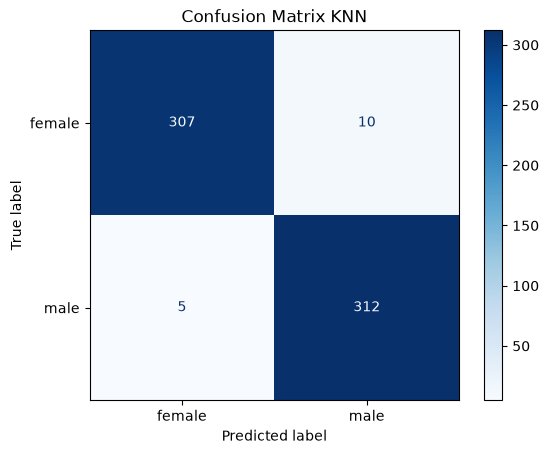

In [10]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap='Blues'
)

plt.title('Confusion Matrix KNN')
plt.show()

In [11]:
mi_scores = mutual_info_classif(
    X_train,
    y_train,
    random_state=42
)

feature_scores = pd.Series(
    mi_scores,
    index=X.columns
).sort_values(ascending=False)

print(feature_scores)

meanfun     0.555423
IQR         0.449243
Q25         0.406964
sd          0.302449
mode        0.177453
sp.ent      0.170729
sfm         0.126971
meanfreq    0.116538
centroid    0.116538
mindom      0.095199
maxdom      0.086317
median      0.081538
skew        0.078524
dfrange     0.077959
meandom     0.056094
kurt        0.041118
maxfun      0.039337
minfun      0.037730
modindx     0.008971
Q75         0.000000
dtype: float64


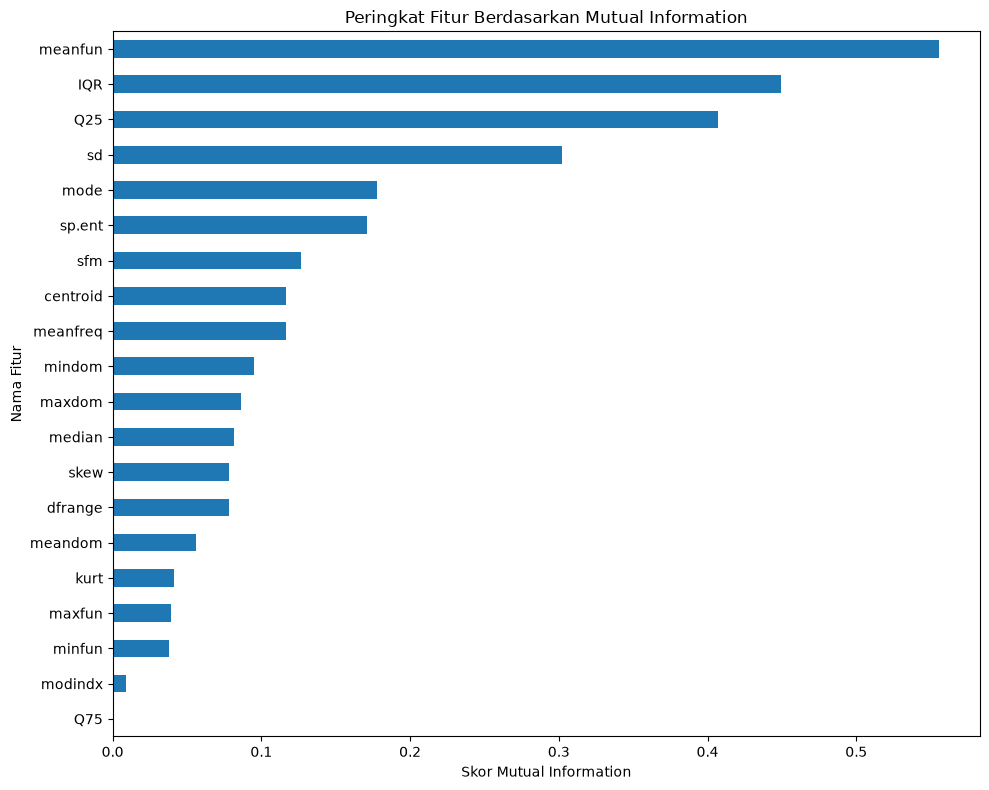

In [12]:
feature_scores.sort_values().plot(
    kind='barh',
    figsize=(10, 8)
)

plt.title('Peringkat Fitur Berdasarkan Mutual Information')
plt.xlabel('Skor Mutual Information')
plt.ylabel('Nama Fitur')
plt.tight_layout()
plt.show()

In [13]:
jumlah_fitur = [3, 4, 5, 6, 8, 10, 12, 15, 20]
nilai_k = range(1, 32, 2)

hasil = []

for n in jumlah_fitur:
    fitur = feature_scores.index[:n]

    scaler_fitur = StandardScaler()

    train_scaled = scaler_fitur.fit_transform(X_train[fitur])
    test_scaled = scaler_fitur.transform(X_test[fitur])

    for k in nilai_k:
        model = KNeighborsClassifier(n_neighbors=k)
        model.fit(train_scaled, y_train)

        prediksi = model.predict(test_scaled)
        akurasi = accuracy_score(y_test, prediksi)

        hasil.append({
            'jumlah_fitur': n,
            'k': k,
            'akurasi': akurasi
        })

hasil_df = pd.DataFrame(hasil)

hasil_df.head()

,jumlah_fitur,k,akurasi
0,3,1,0.968454
1,3,3,0.977918
2,3,5,0.977918
3,3,7,0.979495
4,3,9,0.977918


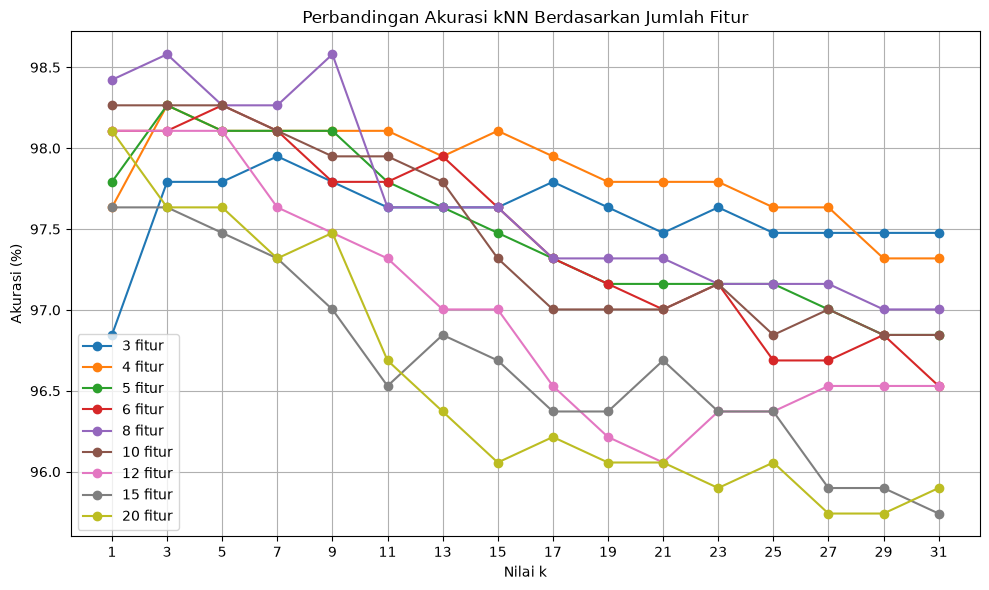

In [14]:
plt.figure(figsize=(10, 6))

for n in jumlah_fitur:
    subset = hasil_df[hasil_df['jumlah_fitur'] == n]

    plt.plot(
        subset['k'],
        subset['akurasi'] * 100,
        marker='o',
        label=f'{n} fitur'
    )

plt.title('Perbandingan Akurasi kNN Berdasarkan Jumlah Fitur')
plt.xlabel('Nilai k')
plt.ylabel('Akurasi (%)')
plt.xticks(list(nilai_k))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [16]:
indeks_terbaik = hasil_df['akurasi'].idxmax()
hasil_terbaik = hasil_df.loc[indeks_terbaik]

print("Jumlah fitur terbaik:", hasil_terbaik['jumlah_fitur'])
print("Nilai k terbaik:", hasil_terbaik['k'])
print("Akurasi terbaik:", round(hasil_terbaik['akurasi'] * 100, 2), "%")

Jumlah fitur terbaik: 8.0
Nilai k terbaik: 3.0
Akurasi terbaik: 98.58 %


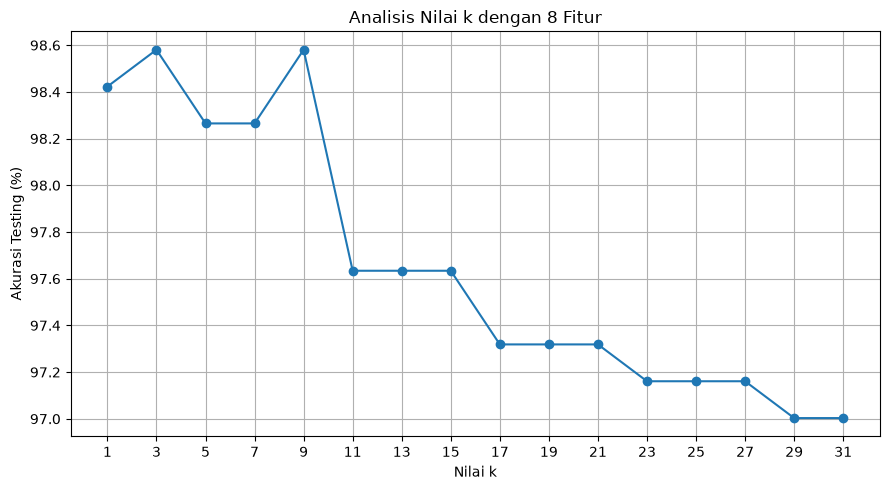

In [17]:
jumlah_fitur_terbaik = int(hasil_terbaik['jumlah_fitur'])

hasil_pilihan = hasil_df[
    hasil_df['jumlah_fitur'] == jumlah_fitur_terbaik
]

plt.figure(figsize=(9, 5))

plt.plot(
    hasil_pilihan['k'],
    hasil_pilihan['akurasi'] * 100,
    marker='o'
)

plt.title(
    f'Analisis Nilai k dengan {jumlah_fitur_terbaik} Fitur'
)
plt.xlabel('Nilai k')
plt.ylabel('Akurasi Testing (%)')
plt.xticks(list(nilai_k))
plt.grid(True)
plt.tight_layout()
plt.show()